# PerfuSense AI · Lesson 4: real movement, real turns

Lessons 1–3 ended with the same open question: the Transformer never beat the simple baseline, and we said that was because **people lie still**. But is that the reason? We can now test it, because of a file we skipped until now.

Every PoPu person has an `others.json`: about 600 frames recorded **between** the labelled positions. Each frame has a clock time. So we can put all of a person's frames back in order and rebuild the **whole session**, including the moments when they really turn over.

In this lesson we:

1. Rebuild each session as one continuous recording at 1 frame per second.
2. Build windows that contain a real turn.
3. Compare the models on still windows and on moving windows.
4. Move from **states** to **events**: detect the turns themselves.

> Research prototype, not a medical device. Nothing here is a clinical claim.

In [1]:
import sys
import inspect
import time

sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras

from perfusense_ai import data as D
from perfusense_ai import model as M


def show(*functions):
    """Print the real source code of our shared functions."""
    for f in functions:
        print(inspect.getsource(f))

## Step 1 · Put one session back together

`load_popu_session` reads all 86 files of a person and sorts every frame by its clock time.

def load_popu_session(person):
    """One person's whole session in time order: frames (n, 64, 27), times (n,), names (n,).

    Names are like 'left3' for labelled snapshots and 'others' for frames between them.
    """
    root = popu_dir() / str(person)
    frames, times, names = [], [], []
    for path in sorted(root.glob("*.json")):
        f, t = load_popu_file(path)
        frames.append(f)
        times.append(t)
        names += [re.sub(r"_\d$", "", path.stem)] * len(f)
    frames, times, names = np.concatenate(frames), np.concatenate(times), np.array(names)
    order = np.argsort(times, kind="stable")
    return frames[order], times[order], names[order]



1474 frames over 17.7 minutes
labelled frames: 850 | frames between positions: 624
first positions in time order: [np.str_('empty1'), np.str_('supine1'), np.str_('supine2'), np.str_('supine3'), np.str_('supine4'), np.str_('supine5'), np.str_('supine6'), np.str_('supine7'), np.str_('prone1'), np.str_('prone2')]


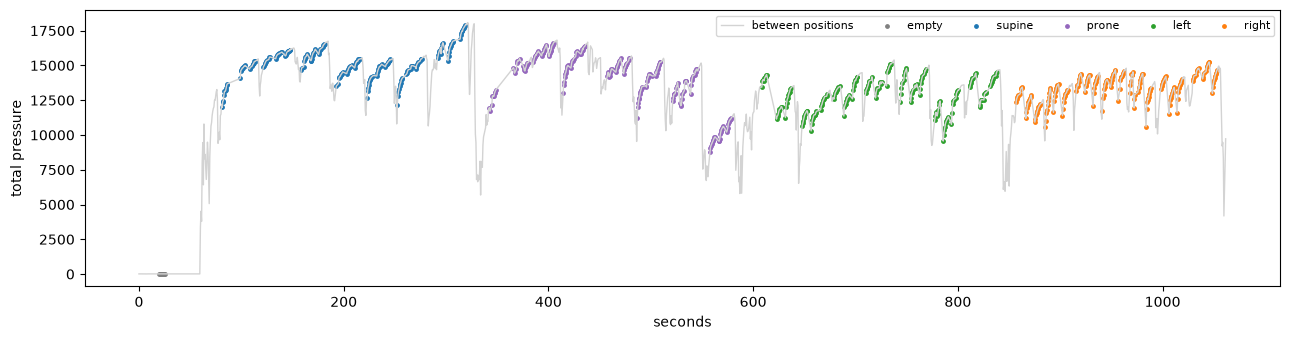

In [2]:
show(D.load_popu_session)

frames, times, names = D.load_popu_session(1)
seconds = times - times[0]
print(f"{len(frames)} frames over {seconds[-1] / 60:.1f} minutes")
print("labelled frames:", int((names != 'others').sum()), "| frames between positions:", int((names == 'others').sum()))

order = [n for i, n in enumerate(names) if n != "others" and (i == 0 or names[i - 1] != n)]
print("first positions in time order:", order[:10])

colours = {"empty": "grey", "supine": "tab:blue", "prone": "tab:purple", "left": "tab:green", "right": "tab:orange"}
total = frames.sum(axis=(1, 2))
plt.figure(figsize=(13, 3.5))
plt.plot(seconds, total, color="lightgrey", lw=1, label="between positions")
for name, colour in colours.items():
    mask = np.char.startswith(names, name)
    plt.scatter(seconds[mask], total[mask], s=6, color=colour, label=name)
plt.xlabel("seconds"); plt.ylabel("total pressure"); plt.legend(ncol=6, fontsize=8); plt.tight_layout(); plt.show()

That is a full session: the empty bed, the person climbing on, then 28 positions in a fixed order. The grey parts between the coloured dots are the real movements, which nobody has labelled.

**One honest limit:** all 60 people followed the same order: supine → prone → left → right. So we see only three kinds of posture change, always in that order.

## Step 2 · One frame per second

Frames arrive about every 0.55 s, with some gaps. The server will send the model **one frame per second**, so we do what a server would do: at each whole second, take the newest frame.

In [3]:
show(D.resample_1hz, D.session_seconds, D.session_windows)

def resample_1hz(frames, times, names):
    """Keep the latest frame at each whole second, like a server that samples once per second."""
    seconds = np.arange(np.ceil(times[0]), times[-1])
    index = np.searchsorted(times, seconds, side="right") - 1
    return frames[index], seconds - seconds[0], names[index]

def session_seconds(person, view):
    """One PoPu person at 1 Hz: small frames (n, 10, 10) and the class of each second.

    `view` works like in windows_from_recordings. Seconds between labelled positions get the class "".
    """
    frames, times, names = load_popu_session(person)
    frames, _, names = resample_1hz(frames, times, names)
    small = view({"person": f"popu-{person}", "frames": frames})
    classes = np.array([re.match(r"[a-z]*", n).group() if n != "others" else "" for n in names])
    return small, classes

def session_windows(person, view, classes=CLASSES_WITH_PRONE, still_stride=10):
    """Windows that END on a labelled second. The label is the posture

In [4]:
popu = D.load_popu()
positions = D.mat_positions(popu)
del popu

patch = D.patch_view(positions)
small, labels = D.session_seconds(1, patch)
print("seconds:", len(small), "| labelled seconds:", int((labels != '').sum()))
print(pd.Series(labels).replace("", "(moving or between)").value_counts().to_dict())

seconds: 1062 | labelled seconds: 696
{'(moving or between)': 366, 'supine': 184, 'left': 180, 'prone': 171, 'right': 155, 'empty': 6}


## Step 3 · Windows that contain a turn

Each window **ends** on a labelled second, and its label is the posture at that last second: *"given the last 30 seconds, what is the posture now?"*

- A **still** window holds one posture.
- A **moving** window starts in the old posture and ends in the new one.

For a moving window, averaging all 30 frames mixes two postures, so the Lesson 1 baseline should struggle. This is exactly where attention could help: it can learn to look at the newest seconds.

But we must be fair. There is a much simpler way to look at the newest seconds: just use them. So we add a third model, **last-frames**, which averages only the newest 5 frames and has no attention at all.

| Model | Sees | Attention |
|---|---|---|
| baseline | the average of all 30 frames | no |
| last-frames | the average of the newest 5 frames | no |
| Transformer | all 30 frames in order | yes |

def build_last_frames(t=30, h=10, w=10, num_classes=3, n=5):
    """No attention: average only the newest n frames, then the same small MLP (Lesson 4)."""
    inp = keras.Input(shape=(t, h, w), name="window")
    x = layers.Reshape((t, h * w))(inp)
    x = layers.Cropping1D((t - n, 0), name="newest_frames")(x)
    x = layers.GlobalAveragePooling1D(name="average_over_time")(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(num_classes, name="logits")(x)
    return keras.Model(inp, out, name="last_frames_mlp")



patch windows: (5772, 30, 10, 10) in 23 s | moving: 1663 | still: 4109
per class: {'supine': np.int64(1436), 'prone': np.int64(1347), 'left': np.int64(1452), 'right': np.int64(1537)}


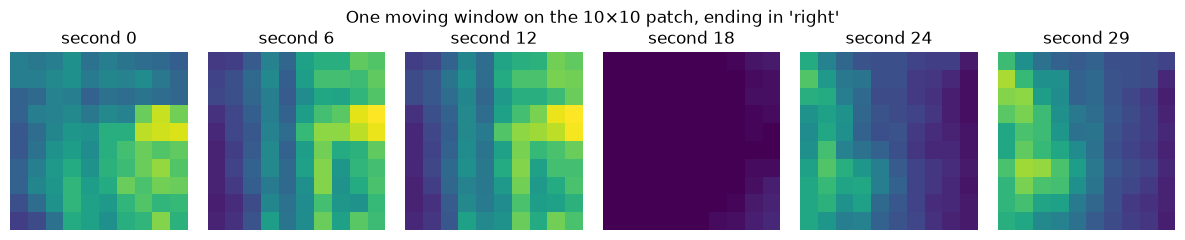

In [5]:
show(M.build_last_frames)

def build_dataset(view):
    X, y, moving, people = [], [], [], []
    for p in range(1, 61):
        a, b, c = D.session_windows(p, view)
        X.append(a); y.append(b); moving.append(c); people += [f"popu-{p}"] * len(b)
    return np.concatenate(X), np.concatenate(y), np.concatenate(moving), np.array(people)

t0 = time.time()
X, y, moving, people = build_dataset(patch)
print(f"patch windows: {X.shape} in {time.time() - t0:.0f} s | moving: {moving.sum()} | still: {(~moving).sum()}")
print("per class:", dict(zip(D.CLASSES_WITH_PRONE, np.bincount(y))))

i = int(np.flatnonzero(moving & (y == D.CLASSES_WITH_PRONE.index("right")))[0])
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for ax, t in zip(axes, [0, 6, 12, 18, 24, 29]):
    ax.imshow(X[i, t], vmin=0, vmax=1); ax.set_title(f"second {t}"); ax.axis("off")
plt.suptitle("One moving window on the 10×10 patch, ending in 'right'"); plt.tight_layout(); plt.show()

## Step 4 · Does attention finally help?

Prone is back, so the models have 4 outputs. We use 3 folds by person to keep the training time reasonable, on both views: the patch (our real mat) and the whole bed.

In [6]:
def compare(X, y, moving, people, view_name):
    rows = []
    n = len(D.CLASSES_WITH_PRONE)
    for name, builder in [("baseline", lambda: M.build_baseline(num_classes=n)),
                          ("last-frames", lambda: M.build_last_frames(num_classes=n)),
                          ("transformer", lambda: M.build_transformer(num_classes=n))]:
        t0 = time.time()
        pred = M.cross_validate(builder, X, y, people, folds=3)
        rows.append({"view": view_name, "model": name, "all": M.score(y, pred)["balanced_acc"],
                     "still": M.score(y[~moving], pred[~moving])["balanced_acc"],
                     "moving": M.score(y[moving], pred[moving])["balanced_acc"],
                     "seconds": round(time.time() - t0)})
    return pd.DataFrame(rows)

patch_results = compare(X, y, moving, people, "patch")
patch_results

,view,model,all,still,moving,seconds
0,patch,baseline,0.784,0.846,0.609,34
1,patch,last-frames,0.865,0.841,0.930,35
2,patch,transformer,0.864,0.866,0.873,107


In [7]:
Xw, yw, mw, pw = build_dataset(D.whole_bed_view)
whole_results = compare(Xw, yw, mw, pw, "whole bed")
del Xw
whole_results

,view,model,all,still,moving,seconds
0,whole bed,baseline,0.903,0.921,0.865,39
1,whole bed,last-frames,0.947,0.939,0.965,29
2,whole bed,transformer,0.949,0.949,0.953,173


Balanced accuracy, 4 postures, 60 people, each tested unseen:

| View | Model | All | Still | Moving |
|---|---|---|---|---|
| Patch | baseline | 78.4 % | 84.6 % | **60.9 %** |
| Patch | last-frames | 86.5 % | 84.1 % | **93.0 %** |
| Patch | Transformer | 86.4 % | 86.6 % | 87.3 % |
| Whole bed | baseline | 90.3 % | 92.1 % | 86.5 % |
| Whole bed | last-frames | 94.7 % | 93.9 % | 96.5 % |
| Whole bed | Transformer | 94.9 % | 94.9 % | 95.3 % |

Three things to read here:

1. **Time really matters when people move.** The averaging baseline collapses to 60.9 % on moving windows, as predicted. The Transformer beats it by 8 points overall and 26 points on moving windows. This is the first time in the project that the Transformer clearly beats the plan's baseline.
2. **But attention is not the reason you might expect.** The simple last-frames model, with no attention, ties the Transformer overall and is **better** on moving windows on the patch (93.0 % against 87.3 %). Most of the gain comes from "look at the newest seconds", not from anything clever.
3. **The Transformer is a little better on still windows** on both views. Patients lie still most of the time, so that counts, but the gap is small (2.5 points on the patch) and this is one run.

Why are moving windows sometimes *easier* than still ones? One likely reason: they end just after a posture change, always on the first variation of that posture, while still windows include all 7 variations. I did not test this.

Adding a fair simple competitor changed the conclusion. Without last-frames we would have said "attention wins".

## Step 5 · Where does the Transformer look?

Train one Transformer on 48 people and look at the attention on the 12 people it never saw. For each second in the window, how much attention does it get on average? (This is the Lesson 1 attention map, averaged over heads, rows and windows.)

last-frames {'balanced_acc': 0.828, 'macro_f1': 0.819}


transformer {'balanced_acc': 0.832, 'macro_f1': 0.83}


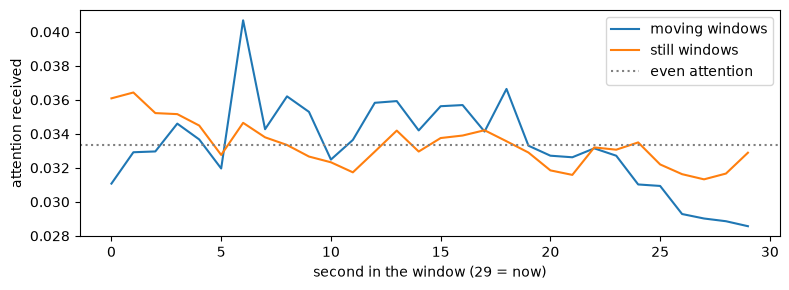

In [8]:
n_classes = len(D.CLASSES_WITH_PRONE)
test_people = [f"popu-{p}" for p in range(49, 61)]
val_people = [f"popu-{p}" for p in range(43, 49)]
te, va = np.isin(people, test_people), np.isin(people, val_people)
tr = ~te & ~va

models = {}
for name, builder in [("last-frames", M.build_last_frames), ("transformer", M.build_transformer)]:
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)
    models[name] = builder(num_classes=n_classes)
    M.train(models[name], X[tr], y[tr], X[va], y[va], batch_size=64)
    print(name, M.score(y[te], M.predict(models[name], X[te])))

def attention_received(model, windows):
    """Average attention each of the 30 seconds receives in the last encoder block."""
    x = model.get_layer("frames_to_tokens")(windows)
    x = model.get_layer("embedding")(x)
    x = model.get_layer("positions")(x)
    x = model.get_layer("encoder_0")(x)
    _, w = model.get_layer("encoder_1")(x, return_attention=True)
    return w.numpy().mean(axis=(0, 1, 2))

plt.figure(figsize=(8, 3))
for mask, label in [(te & moving, "moving windows"), (te & ~moving, "still windows")]:
    plt.plot(attention_received(models["transformer"], X[mask][:300]), label=label)
plt.axhline(1 / 30, color="grey", ls=":", label="even attention")
plt.xlabel("second in the window (29 = now)"); plt.ylabel("attention received"); plt.legend()
plt.tight_layout(); plt.show()

The line is nearly flat, between about 0.03 and 0.04 for every second, and it does **not** rise towards "now". So the Transformer has not learned the simple rule "look at the newest seconds", at least not in a way this picture shows. By the last block each token has already mixed with the others, so attention maps are a weak window into the model. This is why Lesson 1 called them a hint, not proof.

## Step 6 · From states to events: detecting turns

The model gives a **state** every second. The dashboard wants **events**: *"turned at 14:02"*. So we run the model over a whole session, one prediction per second, and look for changes.

A single wrong second must not count as a turn. So we use a **hold time**: a new posture only counts once it has lasted `hold` seconds in a row.

In [9]:
def detect_turns(states, hold):
    """Return (second, new state). A change counts only after `hold` seconds in a row."""
    current, run_state, run, events = states[0], states[0], 0, []
    for t, s in enumerate(states):
        run = run + 1 if s == run_state else 1
        run_state = s
        if s != current and run >= hold:
            events.append((t, int(s)))
            current = s
    return events


def session_states(model, person):
    """Predict the posture for every second of a session, from the first labelled second on."""
    small, labels = D.session_seconds(person, patch)
    start = int(np.flatnonzero(np.isin(labels, D.CLASSES_WITH_PRONE))[0]) + D.T
    windows = np.stack([D.normalise_window(small[t - D.T + 1:t + 1]) for t in range(start, len(small))])
    return M.predict(model, windows), labels[start:]


def true_turns(labels):
    """(last second of the old posture, first second of the new one, new class) for each change."""
    turns, last, last_t = [], None, None
    for t, label in enumerate(labels):
        if label in D.CLASSES_WITH_PRONE:
            if last is not None and label != last:
                turns.append((last_t, t, D.CLASSES_WITH_PRONE.index(label)))
            last, last_t = label, t
    return turns


def score_turns(model, hold, margin=60):
    found = missed = false_alarms = total_seconds = 0
    delays = []
    for person in range(49, 61):
        states, labels = session_states(model, person)
        events = detect_turns(states, hold)
        total_seconds += len(states)
        used = set()
        for old_t, new_t, new_class in true_turns(labels):
            hits = [i for i, (t, s) in enumerate(events)
                    if i not in used and s == new_class and old_t <= t <= new_t + margin]
            if hits:
                used.add(hits[0]); found += 1; delays.append(events[hits[0]][0] - old_t)
            else:
                missed += 1
        false_alarms += len(events) - len(used)
    return {"turns found": found, "missed": missed, "false alarms": false_alarms,
            "false alarms per hour": round(false_alarms / (total_seconds / 3600), 1),
            "median delay (s)": float(np.median(delays)) if delays else None}

rows = []
for name, model in models.items():
    for hold in (1, 10, 20, 30):
        rows.append({"model": name, "hold (s)": hold} | score_turns(model, hold))
turn_table = pd.DataFrame(rows)
turn_table

,model,hold (s),turns found,missed,false alarms,false alarms per hour,median delay (s)
0,last-frames,1,36,0,378,116.6,14.5
1,last-frames,10,31,5,76,23.4,24.0
2,last-frames,20,30,6,41,12.6,34.0
3,last-frames,30,28,8,18,5.6,44.0
4,transformer,1,36,0,269,83.0,14.5
5,transformer,10,33,3,51,15.7,27.0
6,transformer,20,28,8,32,9.9,36.5
7,transformer,30,24,12,24,7.4,45.5


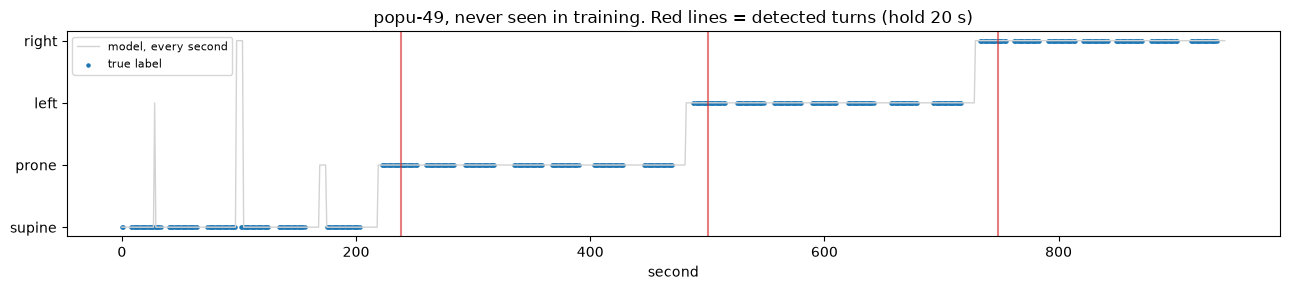

In [10]:
states, labels = session_states(models["transformer"], 49)
truth = np.array([D.CLASSES_WITH_PRONE.index(l) if l in D.CLASSES_WITH_PRONE else -1 for l in labels])
known = truth >= 0

plt.figure(figsize=(13, 3))
plt.plot(states, color="lightgrey", lw=1, label="model, every second")
plt.scatter(np.flatnonzero(known), truth[known], s=5, color="tab:blue", label="true label")
for t, s in detect_turns(states, 20):
    plt.axvline(t, color="tab:red", alpha=.6)
plt.yticks(range(4), D.CLASSES_WITH_PRONE); plt.xlabel("second"); plt.legend(loc="upper left", fontsize=8)
plt.title("popu-49, never seen in training. Red lines = detected turns (hold 20 s)"); plt.tight_layout(); plt.show()

On 12 unseen people there are 36 real posture changes:

| Hold | Last-frames: found / false alarms per hour | Transformer: found / false alarms per hour |
|---|---|---|
| 1 s | 36 of 36 / 116.6 | 36 of 36 / 83.0 |
| 10 s | 31 / 23.4 | 33 / 15.7 |
| 20 s | 30 / 12.6 | 28 / 9.9 |
| 30 s | 28 / 5.6 | 24 / 7.4 |

- **Hold time is a trade-off, and this is the classic alarm problem.** A short hold finds everything and cries wolf. A long hold is calm, but misses turns and reports late (median delay 24–27 s at 10 s, about 45 s at 30 s).
- **Neither model wins.** At 10 s the Transformer is better, at 30 s last-frames is.
- **It is not ready to count turns on its own.** Even the calmest row here gives a false turn about every 10 minutes. PoPu people also change variation and shift about 20 times inside each posture, which may be harder than a calm patient, but we cannot claim that makes it safe.
- Turning is slow, so a delay of 30 seconds does not matter for a 2-hour turn schedule. The hold can be long. That choice belongs in the server settings, not hard-coded, and the team should decide it.

## What we learned

- **`others.json` was the hidden treasure.** It turned PoPu from still recordings into 60 real sessions of about 17 minutes each.
- **Lessons 1–3 said "attention does not help because people lie still". That was right.** With movement in the data, time matters a lot: the averaging baseline falls to 60.9 %.
- **The Transformer beats the plan's baseline, but not the best simple model.** It ties last-frames overall. This is a fair and useful result to report.
- **States and events are different problems.** An 86 % state model still needs a hold rule to give usable events.

**Limits:** all sessions follow one fixed order (supine → prone → left → right), so the model may partly learn that order. People moved themselves on request. A patient being turned by a nurse will look different. The test here is 12 people.

## Your turn

1. Change `n` in `build_last_frames` from 5 to 1, then to 15.
2. Train with `T = 15` (Lesson 1's exercise) on moving windows.
3. Give `detect_turns` a rule that ignores changes shorter than the time between two turns a nurse could really make. What is a fair value, and who should decide it?